In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
t2m_path = r"ds\USA\T2M.csv"
rh2m_path = r"ds\USA\RH2M.csv"
ws2m_path = r"ds\USA\WS2M.csv"
radiation_path = r"ds\USA\ALLSKY_SFC_SW_DWN.csv"
rainfall_path = r"ds\USA\PRECTOTCORR.csv"

In [3]:
t2m = pd.read_csv(t2m_path, skiprows=9)
rh2m = pd.read_csv(rh2m_path, skiprows=9)
ws2m = pd.read_csv(ws2m_path, skiprows=9)
radiation = pd.read_csv(radiation_path, skiprows=9)
rainfall = pd.read_csv(rainfall_path, skiprows=9)

FileNotFoundError: [Errno 2] No such file or directory: 'ds\\USA\\T2M.csv'

In [ ]:
print("T2M:")
display(t2m.head())

print("RH2M:")
display(rh2m.head())

print("WS2M:")
display(ws2m.head())

print("Radiation:")
display(radiation.head())

print("Rainfall:")
display(rainfall.head())

T2M:


,YEAR,DOY,T2M
0,2018,1,13.59
1,2018,2,16.65
2,2018,3,16.62
3,2018,4,17.57
4,2018,5,16.71


RH2M:


,YEAR,DOY,RH2M
0,2018,1,37.51
1,2018,2,34.38
2,2018,3,31.11
3,2018,4,53.09
4,2018,5,70.86


WS2M:


,YEAR,DOY,WS2M
0,2018,1,1.07
1,2018,2,1.06
2,2018,3,1.23
3,2018,4,1.25
4,2018,5,1.05


Radiation:


,YEAR,DOY,ALLSKY_SFC_SW_DWN
0,2018,1,9.42
1,2018,2,5.10
2,2018,3,4.83
3,2018,4,7.88
4,2018,5,9.76


Rainfall:


,YEAR,DOY,PRECTOTCORR
0,2018,1,0.00
1,2018,2,0.00
2,2018,3,0.08
3,2018,4,2.71
4,2018,5,1.28


In [ ]:
print(t2m.columns)
print(rh2m.columns)
print(ws2m.columns)
print(radiation.columns)
print(rainfall.columns)

Index(['YEAR', 'DOY', 'T2M'], dtype='object')
Index(['YEAR', 'DOY', 'RH2M'], dtype='object')
Index(['YEAR', 'DOY', 'WS2M'], dtype='object')
Index(['YEAR', 'DOY', 'ALLSKY_SFC_SW_DWN'], dtype='object')
Index(['YEAR', 'DOY', 'PRECTOTCORR'], dtype='object')


In [ ]:
t2m = t2m[['YEAR', 'DOY', 'T2M']]
rh2m = rh2m[['YEAR', 'DOY', 'RH2M']]
ws2m = ws2m[['YEAR', 'DOY', 'WS2M']]
radiation = radiation[['YEAR', 'DOY', 'ALLSKY_SFC_SW_DWN']]
rainfall = rainfall[['YEAR', 'DOY', 'PRECTOTCORR']]

In [ ]:
weather = t2m.merge(
    rh2m,
    on=['YEAR', 'DOY'],
    how='inner'
)

weather = weather.merge(
    ws2m,
    on=['YEAR', 'DOY'],
    how='inner'
)

weather = weather.merge(
    radiation,
    on=['YEAR', 'DOY'],
    how='inner'
)

weather = weather.merge(
    rainfall,
    on=['YEAR', 'DOY'],
    how='inner'
)

In [ ]:
weather.head()


,YEAR,DOY,T2M,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
0,2018,1,13.59,37.51,1.07,9.42,0.00
1,2018,2,16.65,34.38,1.06,5.10,0.00
2,2018,3,16.62,31.11,1.23,4.83,0.08
3,2018,4,17.57,53.09,1.25,7.88,2.71
4,2018,5,16.71,70.86,1.05,9.76,1.28


In [ ]:
weather.shape

(2191, 7)

In [ ]:
weather[['YEAR', 'DOY']].agg(['min', 'max'])

,YEAR,DOY
min,2018,1
max,2023,366


In [ ]:
weather.tail()

,YEAR,DOY,T2M,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
2186,2023,361,12.75,57.16,1.17,6.76,0.00
2187,2023,362,13.70,62.53,1.18,9.63,0.00
2188,2023,363,14.82,63.26,1.27,6.92,0.05
2189,2023,364,10.98,84.62,0.74,5.77,6.42
2190,2023,365,10.22,72.62,0.80,5.64,0.13


In [ ]:
weather.isna().sum()

YEAR                 0
DOY                  0
T2M                  0
RH2M                 0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
PRECTOTCORR          0
dtype: int64

In [ ]:
(weather == -999).sum()

YEAR                 0
DOY                  0
T2M                  0
RH2M                 0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
PRECTOTCORR          0
dtype: int64

In [ ]:
weather['Date'] = (
    pd.to_datetime(weather['YEAR'].astype(str), format='%Y')
    + pd.to_timedelta(weather['DOY'] - 1, unit='D')
)
weather[['YEAR', 'DOY', 'Date']].head()

,YEAR,DOY,Date
0,2018,1,2018-01-01
1,2018,2,2018-01-02
2,2018,3,2018-01-03
3,2018,4,2018-01-04
4,2018,5,2018-01-05


In [ ]:
weather = weather.rename(columns={
    'T2M': 'Temperature',
    'RH2M': 'Humidity',
    'WS2M': 'WindSpeed',
    'ALLSKY_SFC_SW_DWN': 'SolarRadiation',
    'PRECTOTCORR': 'Rainfall'
})
weather.head()

,YEAR,DOY,Temperature,Humidity,WindSpeed,SolarRadiation,Rainfall,Date
0,2018,1,13.59,37.51,1.07,9.42,0.00,2018-01-01
1,2018,2,16.65,34.38,1.06,5.10,0.00,2018-01-02
2,2018,3,16.62,31.11,1.23,4.83,0.08,2018-01-03
3,2018,4,17.57,53.09,1.25,7.88,2.71,2018-01-04
4,2018,5,16.71,70.86,1.05,9.76,1.28,2018-01-05


In [ ]:
weather['Temperature_K'] = weather['Temperature'] + 273.15
weather['es'] = (
    0.6108 *
    np.exp(
        (17.27 * weather['Temperature']) /
        (weather['Temperature'] + 237.3)
    )
)
weather['ea'] = weather['es'] * weather['Humidity'] / 100
weather['VPD'] = weather['es'] - weather['ea']
weather[['Temperature', 'Humidity', 'es', 'ea', 'VPD']].head()

,Temperature,Humidity,es,ea,VPD
0,13.59,37.51,1.556565,0.583867,0.972697
1,16.65,34.38,1.895165,0.651558,1.243607
2,16.62,31.11,1.891555,0.588463,1.303093
3,17.57,53.09,2.008841,1.066494,0.942347
4,16.71,70.86,1.902403,1.348043,0.554360


In [ ]:
elevation = 249.47  # metres

pressure = 101.3 * (
    (293 - 0.0065 * elevation) / 293
) ** 5.26

pressure

98.3856588314699

In [ ]:
gamma = 0.665e-3 * pressure

gamma

0.06542646312292748

In [ ]:
weather['Delta'] = (
    4098 * weather['es']
    / (weather['Temperature'] + 237.3) ** 2
)
weather[['Temperature', 'es', 'Delta']].head()

,Temperature,es,Delta
0,13.59,1.556565,0.101338
1,16.65,1.895165,0.120427
2,16.62,1.891555,0.120226
3,17.57,2.008841,0.126730
4,16.71,1.902403,0.120829


# Solar geometry

In [ ]:
latitude = 36.5
longitude = -119.5
elevation = 249.47

latitude_rad = np.radians(latitude)

In [ ]:
weather['dr'] = (
    1 + 0.033 *
    np.cos(
        2 * np.pi * weather['DOY'] / 365
    )
)

In [ ]:
weather['solar_declination'] = (
    0.409 *
    np.sin(
        2 * np.pi * weather['DOY'] / 365 - 1.39
    )
)

In [ ]:
weather['sunset_angle'] = np.arccos(
    -np.tan(latitude_rad) *
    np.tan(weather['solar_declination'])
)

In [ ]:
Gsc = 0.0820  # MJ m^-2 min^-1

weather['Ra'] = (
    (24 * 60 / np.pi)
    * Gsc
    * weather['dr']
    * (
        weather['sunset_angle'] *
        np.sin(latitude_rad) *
        np.sin(weather['solar_declination'])
        +
        np.cos(latitude_rad) *
        np.cos(weather['solar_declination']) *
        np.sin(weather['sunset_angle'])
    )
)

In [ ]:
weather[['DOY', 'Ra']].head()

,DOY,Ra
0,1,16.000141
1,2,16.055069
2,3,16.114381
3,4,16.178059
4,5,16.246088


# Net radiation

In [ ]:
weather['Rs'] = weather['SolarRadiation']

In [ ]:
weather['Rso'] = (
    (0.75 + 2e-5 * elevation)
    * weather['Ra']
)

In [ ]:
weather['Rns'] = (
    (1 - 0.23) * weather['Rs']
)

In [ ]:
sigma = 4.903e-9  # MJ K^-4 m^-2 day^-1

weather['Rnl'] = (
    sigma
    * weather['Temperature_K'] ** 4
    * (0.34 - 0.14 * np.sqrt(weather['ea']))
    * (
        1.35 * np.minimum(
            weather['Rs'] / weather['Rso'],
            1
        ) - 0.35
    )
)

In [ ]:
weather['Rn'] = (
    weather['Rns'] - weather['Rnl']
)
weather[
    ['Rs', 'Rso', 'Rns', 'Rnl', 'Rn']
].head()

,Rs,Rso,Rns,Rnl,Rn
0,9.42,12.079937,7.2534,5.427617,1.825783
1,5.10,12.121407,3.9270,1.711321,2.215679
2,4.83,12.166187,3.7191,1.495187,2.223913
3,7.88,12.214263,6.0676,3.565549,2.502051
4,9.76,12.265624,7.5152,4.448044,3.067156


In [ ]:
weather['ET0'] = (
    (
        0.408
        * weather['Delta']
        * weather['Rn']
        +
        gamma
        * (
            900
            / (weather['Temperature'] + 273)
        )
        * weather['WindSpeed']
        * weather['VPD']
    )
    /
    (
        weather['Delta']
        +
        gamma
        * (1 + 0.34 * weather['WindSpeed'])
    )
)

In [ ]:
weather[['Date', 'Temperature', 'Humidity', 'WindSpeed', 'Rn', 'ET0']].head(10)

,Date,Temperature,Humidity,WindSpeed,Rn,ET0
0,2018-01-01,13.59,37.51,1.07,1.825783,1.518274
1,2018-01-02,16.65,34.38,1.06,2.215679,1.799389
2,2018-01-03,16.62,31.11,1.23,2.223913,2.041937
3,2018-01-04,17.57,53.09,1.25,2.502051,1.673366
4,2018-01-05,16.71,70.86,1.05,3.067156,1.285768
5,2018-01-06,14.77,75.17,1.10,2.544190,1.041015
6,2018-01-07,14.64,55.75,1.18,2.574412,1.460959
7,2018-01-08,14.75,73.24,2.72,2.429879,1.525597
8,2018-01-09,12.28,76.07,2.47,2.640545,1.285486
9,2018-01-10,10.81,79.26,1.30,2.949622,0.976312


In [ ]:
weather['ET0'].describe()

count    2191.000000
mean        3.957257
std         2.326159
min         0.446728
25%         1.772880
50%         3.641713
75%         6.070401
max         9.525724
Name: ET0, dtype: float64

In [ ]:
weather['ET0'].min(), weather['ET0'].max()

(np.float64(0.44672810751938563), np.float64(9.525723839367137))

In [ ]:
weather['ET0'].isna().sum()

np.int64(0)

In [ ]:
(weather['ET0'] < 0).sum()

np.int64(0)

In [ ]:
weather.groupby(weather['Date'].dt.month)['ET0'].mean().round(2)

Date
1     1.25
2     1.83
3     2.48
4     4.04
5     5.45
6     7.05
7     7.49
8     6.40
9     4.95
10    3.37
11    1.89
12    1.15
Name: ET0, dtype: float64

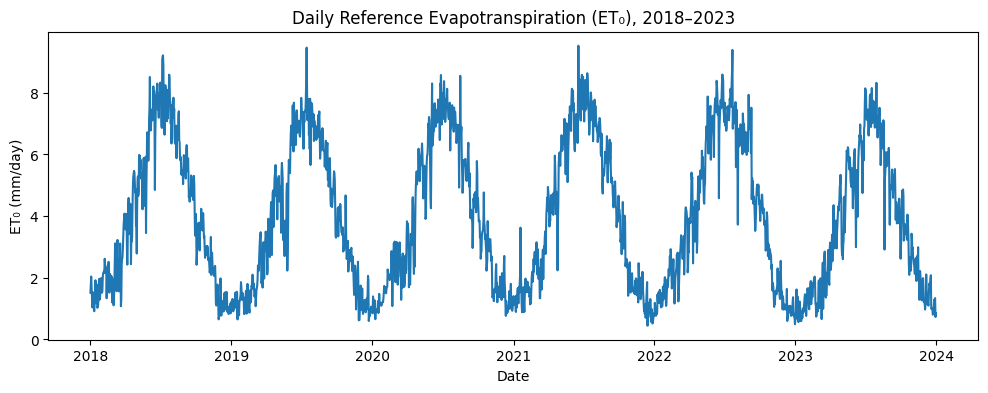

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(weather['Date'], weather['ET0'])

plt.xlabel('Date')
plt.ylabel('ET₀ (mm/day)')
plt.title('Daily Reference Evapotranspiration (ET₀), 2018–2023')

plt.show()

In [ ]:
weather_final = weather[
    [
        'Date',
        'Temperature',
        'Humidity',
        'WindSpeed',
        'SolarRadiation',
        'Rainfall',
        'ET0'
    ]
].copy()

weather_final.to_csv('weather_eto.csv', index=False)
weather_final.head()

,Date,Temperature,Humidity,WindSpeed,SolarRadiation,Rainfall,ET0
0,2018-01-01,13.59,37.51,1.07,9.42,0.00,1.518274
1,2018-01-02,16.65,34.38,1.06,5.10,0.00,1.799389
2,2018-01-03,16.62,31.11,1.23,4.83,0.08,2.041937
3,2018-01-04,17.57,53.09,1.25,7.88,2.71,1.673366
4,2018-01-05,16.71,70.86,1.05,9.76,1.28,1.285768


In [ ]:
eto_thresholds = {
    'low_to_moderate': weather['ET0'].quantile(0.33),
    'moderate_to_high': weather['ET0'].quantile(0.66)
}

eto_thresholds

{'low_to_moderate': np.float64(2.231133901283059),
 'moderate_to_high': np.float64(5.158432087433082)}

In [ ]:
def classify_eto(eto):
    if eto < 2.231133901283059:
        return 'Low'
    elif eto < 5.158432087433082:
        return 'Moderate'
    else:
        return 'High'

In [ ]:
print(classify_eto(1.5))
print(classify_eto(3.5))
print(classify_eto(7.0))

Low
Moderate
High


In [ ]:
def combine_demand(lai_demand, eto_demand):

    demand_level = {
        'Low': 1,
        'Moderate': 2,
        'High': 3
    }

    final_level = max(
        demand_level[lai_demand],
        demand_level[eto_demand]
    )

    if final_level == 1:
        return 'Low'
    elif final_level == 2:
        return 'Moderate'
    else:
        return 'High'

In [ ]:
print(combine_demand('Low', 'Low'))
print(combine_demand('Low', 'High'))
print(combine_demand('Moderate', 'Low'))
print(combine_demand('High', 'Low'))

Low
High
Moderate
High


In [ ]:
weather['Rainfall'].describe()


count    2191.000000
mean        1.226960
std         4.995314
min         0.000000
25%         0.000000
50%         0.000000
75%         0.060000
max        82.380000
Name: Rainfall, dtype: float64

In [ ]:
weather['Rainfall'].max()

np.float64(82.38)

In [ ]:
(weather['Rainfall'] > 0).sum()

np.int64(804)

In [ ]:
weather.loc[weather['Rainfall'] > 0, 'Rainfall'].describe()

count    804.000000
mean       3.343619
std        7.808198
min        0.010000
25%        0.040000
50%        0.320000
75%        2.757500
max       82.380000
Name: Rainfall, dtype: float64

In [ ]:
rain_threshold = weather.loc[
    weather['Rainfall'] > 0, 'Rainfall'
].quantile(0.75)

rain_threshold

np.float64(2.7575)

In [ ]:
def adjust_for_rainfall(demand, rainfall):

    if rainfall >= rain_threshold:
        if demand == 'High':
            return 'Moderate'
        elif demand == 'Moderate':
            return 'Low'
        else:
            return 'Low'

    return demand

In [ ]:
print(adjust_for_rainfall('High', 0))
print(adjust_for_rainfall('High', 5))
print(adjust_for_rainfall('Moderate', 10))
print(adjust_for_rainfall('Low', 10))

High
Moderate
Low
Low
